# 13 — exp0c: worst-case straddle

The requirement in exp1 is the worst case over the heading, g(x) = max over psi of f(x, psi), but the straddle learns the boundary of f over the whole space. Here x3 of the exp0 test cases plays the heading, and two acquisitions are compared on the worst-case boundary, where the truth is known:

* **A**: the straddle as in exp1, worst case read from the surrogate afterwards;
* **B**: the worst-case straddle (`acquisition="worst_case"`): each design x is scored by the straddle of g, from the bounds max over x3 of mu -+ 1.96 s on 21 values of x3, and sampled at the x3 with the highest mu + 1.96 s (StableOpt's parameter-robust variant, Bogunovic et al. 2018).

hs_dim, 10 seeds, 36 initial samples, 250 samples, no early stopping. Runs cached in `results/exp0c_runs.pkl`.

In [1]:
import os
import pickle
import sys
import time
from pathlib import Path

os.environ["VECLIB_MAXIMUM_THREADS"] = "1"          # one BLAS thread per worker: the workers are the parallelism
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"                # Linux numpy: OpenBLAS or MKL
os.environ["MKL_NUM_THREADS"] = "1"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from joblib import Parallel, delayed
from mvlse import fit_surrogate, run_lse, score_level_set
from mvlse.problems import get_problem

sys.path.insert(0, str(Path.cwd().parent))
import common
import config

P = config.EXPERIMENTS["exp0_verify"]                # same seeds, 250 samples, 1 initial per category as exp0
ENV = "x3"                                           # the third continuous variable plays the heading
N_ENV = 21                                           # environment grid the worst-case acquisition maximises over
CHECKPOINTS = [36, 50, 75, 100, 125, 150, 175, 200, 225, 250]
CACHE = Path("results/exp0c_runs.pkl")
N_WORKERS = int(os.environ.get("TRC_N_JOBS", "6"))

# Test cases. "edge": the worst x3 is x3 = 0 for every design, as 2 deg is for 20 kt in exp1.
# "moving": x3 is replaced by |x3 - x2|, so the worst x3 sits at x3 = x2: inside the range and
# different for every design.
CASES = {
    "goldstein36_graded / edge": ("goldstein36_graded", False),
    "goldstein36_flip / edge": ("goldstein36_flip", False),
    "goldstein36_graded / moving": ("goldstein36_graded", True),
}
CONDITIONS = {"A: straddle, max afterwards": "straddle", "B: worst-case straddle": "worst_case"}
try:
    print(common.code_state())
except Exception:                                    # a copy of the working tree without .git (server run)
    import mvlse
    print("mvlse imported from", mvlse.__file__)

mvlse imported from /home/mfrahman/TRC/nb13_work/mvlse/__init__.py


In [2]:
# Truth of the worst case g(x) = max over x3 of f(x, x3), on a design grid: 15 x 15 values of
# (x1, x2) for each of the 36 categories, x3 maximised on 61 values. The surrogate's worst case is
# read the same way on 41 values of x3.
E_TRUE, E_READ = np.linspace(0, 1, 61), np.linspace(0, 1, 41)


def response(case):
    prob_name, moving = CASES[case]
    prob = get_problem(prob_name)

    def f(w):
        w = np.array(w, float)
        if moving:
            w[:, 2] = np.abs(w[:, 2] - w[:, 1])
        return prob.truth(w)

    return prob, f


def design_grid(space):
    g = np.linspace(0, 1, 15)
    g1, g2 = np.meshgrid(g, g, indexing="ij")
    cats = np.array(space.categories, float)
    xy = np.column_stack([g1.ravel(), g2.ravel()])
    return np.column_stack([np.tile(xy, (len(cats), 1)), np.repeat(cats, len(xy), axis=0)])


def with_env(designs, e):
    return np.insert(designs, 2, e, axis=1)


def worst(fn, designs, e_grid):
    return np.max([fn(with_env(designs, e)) for e in e_grid], axis=0)


TRUTH = {}
for case in CASES:
    prob, f = response(case)
    d = design_grid(prob.space)
    TRUTH[case] = worst(f, d, E_TRUE)
    print(f"{case:30s} {len(d)} designs, {np.mean(TRUTH[case] <= prob.threshold):.1%} acceptable in the worst case")

goldstein36_graded / edge      8100 designs, 39.5% acceptable in the worst case


goldstein36_flip / edge        8100 designs, 45.0% acceptable in the worst case


goldstein36_graded / moving    8100 designs, 39.7% acceptable in the worst case


In [3]:
# Every (case, condition, seed) to 250 samples, no early stopping. The worst-case boundary is
# scored at checkpoints by refitting the surrogate to the first n samples.
def one_run(case, cond, seed):
    prob, f = response(case)
    space = prob.space
    blackbox = lambda points: list(f(space.encode(points)))
    t0 = time.perf_counter()
    acq = CONDITIONS[cond]
    res = run_lse(space, blackbox, threshold=prob.threshold, method=config.LSE["method"], seed=seed,
                  acquisition=acq, environment=ENV if acq == "worst_case" else None, n_environment=N_ENV,
                  max_evaluations=P["max_evaluations"], n_init_per_category=P["n_init_per_category"],
                  flip_tolerance=-1.0, stop_when_confident=False, verbose=False)
    designs, truth = design_grid(space), TRUTH[case]
    out = {"n": [], "f1": [], "false_safe": [], "false_unsafe": []}
    for n in CHECKPOINTS:
        model = fit_surrogate(config.LSE["method"], space, res.w[:n], res.y[:n], rng=np.random.default_rng(0))
        mu = worst(lambda w: model.predict(w)[0], designs, E_READ)
        s = score_level_set(mu, truth, prob.threshold)
        out["n"].append(n); out["f1"].append(s.f1)
        out["false_safe"].append(float(np.mean((mu <= prob.threshold) & (truth > prob.threshold))))
        out["false_unsafe"].append(float(np.mean((mu > prob.threshold) & (truth <= prob.threshold))))
    out.update(w=res.w, y=res.y, n_initial=res.n_initial, seconds=time.perf_counter() - t0,
               max_straddle=[r.max_straddle for r in res.rounds])
    return (case, cond, seed), out


done = pickle.loads(CACHE.read_bytes()) if CACHE.exists() else {}
jobs = [(c, k, s) for c in CASES for k in CONDITIONS for s in P["seeds"]]
todo = [j for j in jobs if j not in done]
print(f"{len(jobs) - len(todo)} of {len(jobs)} runs cached, {len(todo)} to run on {N_WORKERS} workers", flush=True)
t0 = time.perf_counter()
for key, rec in Parallel(n_jobs=N_WORKERS, return_as="generator_unordered")(delayed(one_run)(*j) for j in todo):
    done[key] = rec
    CACHE.write_bytes(pickle.dumps(done))
    print(f"[{(time.perf_counter() - t0) / 60:5.1f} min] {key[0]:28s} {key[1][:2]} seed {key[2]:2d}: "
          f"F1 {rec['f1'][-1]:.4f} [{rec['seconds'] / 60:.1f} min]", flush=True)
runs = done

0 of 60 runs cached, 60 to run on 60 workers


[ 68.2 min] goldstein36_flip / edge      B: seed  9: F1 0.9963 [68.2 min]


[ 68.4 min] goldstein36_flip / edge      B: seed  6: F1 0.9967 [68.3 min]


[ 69.1 min] goldstein36_flip / edge      B: seed  3: F1 0.9964 [69.0 min]


[ 69.6 min] goldstein36_graded / edge    B: seed  4: F1 0.9970 [69.6 min]


[ 69.7 min] goldstein36_flip / edge      B: seed  8: F1 0.9985 [69.7 min]


... (51 outputs left out)

[133.9 min] goldstein36_graded / moving  B: seed  6: F1 0.9865 [133.9 min]


[136.8 min] goldstein36_graded / moving  B: seed  2: F1 0.9866 [136.8 min]


[142.7 min] goldstein36_graded / moving  B: seed  1: F1 0.9863 [142.6 min]


[148.9 min] goldstein36_graded / moving  B: seed  4: F1 0.9861 [148.9 min]


In [4]:
# Worst-case classification on the design grid (mean +- sd over seeds).
def first_n(r, thr):
    hits = [n for n, v in zip(r["n"], r["f1"]) if v >= thr]
    return hits[0] if hits else np.nan

def mean_sd(v, fmt):
    v = np.asarray(v, float)
    hit = v[~np.isnan(v)]
    if len(hit) == 0:
        return "never"
    s = f"{fmt.format(hit.mean())} +- {fmt.format(hit.std())}"
    return s if len(hit) == len(v) else s + f" ({len(hit)}/{len(v)} runs)"

rows = []
for case in CASES:
    for cond in CONDITIONS:
        rs = [runs[case, cond, s] for s in P["seeds"]]
        rows.append({
            "case": case, "condition": cond,
            "F1 at 100": mean_sd([np.interp(100, r["n"], r["f1"]) for r in rs], "{:.4f}"),
            "F1 at 250": mean_sd([r["f1"][-1] for r in rs], "{:.4f}"),
            "samples to F1 >= 0.99": mean_sd([first_n(r, 0.99) for r in rs], "{:.0f}"),
            "false safe at 250": f"{100 * np.mean([r['false_safe'][-1] for r in rs]):.2f}%",
            "false unsafe at 250": f"{100 * np.mean([r['false_unsafe'][-1] for r in rs]):.2f}%",
            "minutes per run": f"{np.mean([r['seconds'] for r in rs]) / 60:.1f}",
        })
table = pd.DataFrame(rows).set_index(["case", "condition"])
table.to_csv("results/exp0c_summary.csv")
table

F1 at 100  \
case                        condition                                       
goldstein36_graded / edge   A: straddle, max afterwards  0.9957 +- 0.0010   
                            B: worst-case straddle       0.9991 +- 0.0003   
goldstein36_flip / edge     A: straddle, max afterwards  0.9978 +- 0.0009   
                            B: worst-case straddle       0.9996 +- 0.0002   
goldstein36_graded / moving A: straddle, max afterwards  0.8924 +- 0.1744   
                            B: worst-case straddle       0.9684 +- 0.0059   

                                                                F1 at 250  \
case                        condition                                       
goldstein36_graded / edge   A: straddle, max afterwards  0.9992 +- 0.0004   
                            B: worst-case straddle       0.9926 +- 0.0130   
goldstein36_flip / edge     A: straddle, max afterwards  0.9992 +- 0.0007   
                            B: worst-case straddle       0.9978 +- 0.0010   
goldstein36_graded / moving A: straddle, max afterwards  0.9712 +- 0.0036   
                            B: worst-case straddle       0.9865 +- 0.0010   

                                                        samples to F1 >= 0.99  \
case                        condition                                           
goldstein36_graded / edge   A: straddle, max afterwards               98 +- 8   
                            B: worst-case straddle                    75 +- 0   
goldstein36_flip / edge     A: straddle, max afterwards               72 +- 8   
                            B: worst-case straddle                   68 +- 11   
goldstein36_graded / moving A: straddle, max afterwards                 never   
                            B: worst-case straddle                      never   

                                                        false safe at 250  \
case                        condition                                       
goldstein36_graded / edge   A: straddle, max afterwards             0.03%   
                            B: worst-case straddle                  0.20%   
goldstein36_flip / edge     A: straddle, max afterwards             0.05%   
                            B: worst-case straddle                  0.10%   
goldstein36_graded / moving A: straddle, max afterwards             2.00%   
                            B: worst-case straddle                  1.00%   

                                                        false unsafe at 250  \
case                        condition                                         
goldstein36_graded / edge   A: straddle, max afterwards               0.03%   
                            B: worst-case straddle                    0.37%   
goldstein36_flip / edge     A: straddle, max afterwards               0.02%   
                            B: worst-case straddle                    0.10%   
goldstein36_graded / moving A: straddle, max afterwards               0.34%   
                            B: worst-case straddle                    0.09%   

                                                        minutes per run  
case                        condition                                    
goldstein36_graded / edge   A: straddle, max afterwards           109.5  
                            B: worst-case straddle                 76.7  
goldstein36_flip / edge     A: straddle, max afterwards           116.3  
                            B: worst-case straddle                 72.3  
goldstein36_graded / moving A: straddle, max afterwards           126.1  
                            B: worst-case straddle                133.4

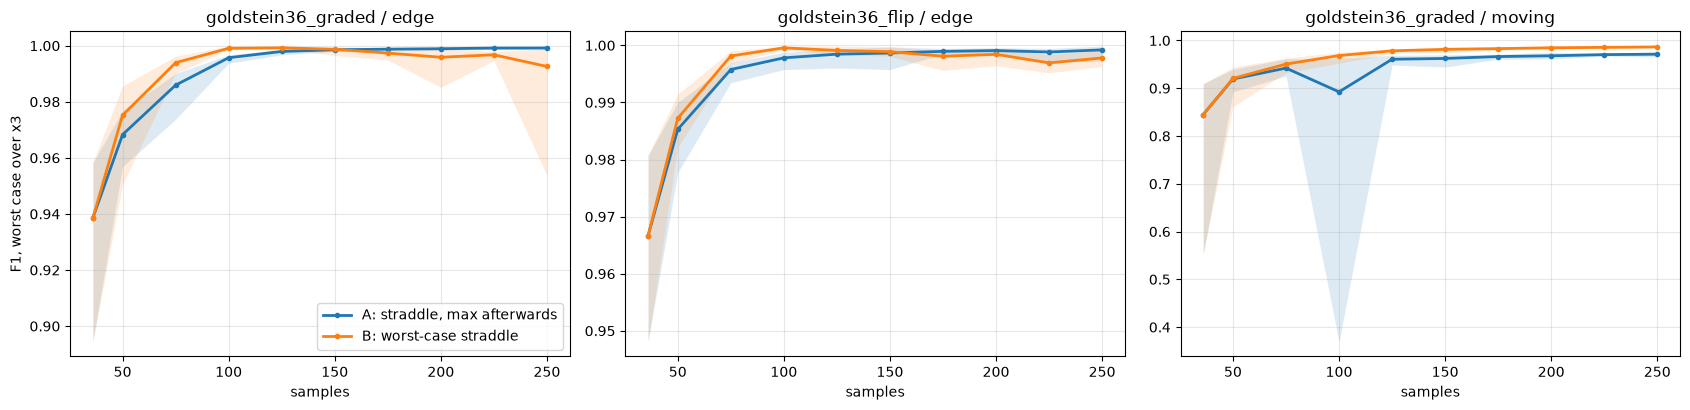

In [5]:
# F1 of the worst-case classification against samples; conditions differ by colour only.
colors = {c: f"C{i}" for i, c in enumerate(CONDITIONS)}
fig, axes = plt.subplots(1, len(CASES), figsize=(17, 4.2), squeeze=False)
for ax, case in zip(axes.flat, CASES):
    for cond in CONDITIONS:
        c = np.array([runs[case, cond, s]["f1"] for s in P["seeds"]])
        ax.plot(CHECKPOINTS, c.mean(axis=0), color=colors[cond], lw=2, marker="o", ms=3, label=cond)
        ax.fill_between(CHECKPOINTS, c.min(axis=0), c.max(axis=0), color=colors[cond], alpha=0.15, lw=0)
    ax.set_title(case); ax.set_xlabel("samples"); ax.grid(alpha=0.3)
axes.flat[0].set_ylabel("F1, worst case over x3"); axes.flat[0].legend(loc="lower right")
plt.tight_layout(); plt.savefig("results/exp0c_f1_vs_samples.pdf"); plt.show()

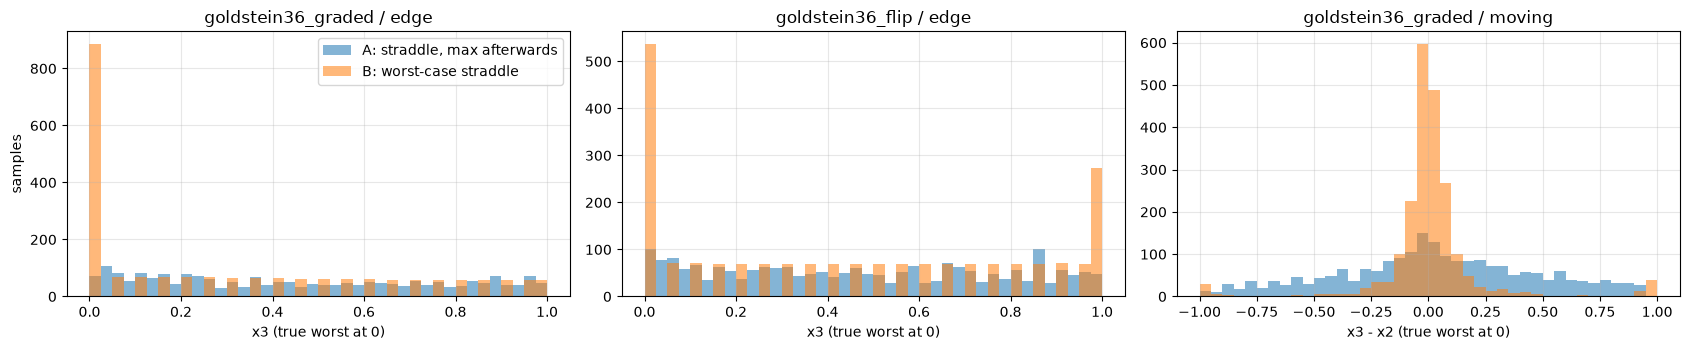

In [6]:
# Where the samples went along x3 (after the 36 initial ones), all seeds. For "moving" the
# distance to the true worst x3 (= x2) is shown instead.
fig, axes = plt.subplots(1, len(CASES), figsize=(17, 3.6), squeeze=False)
for ax, case in zip(axes.flat, CASES):
    moving = CASES[case][1]
    for cond in CONDITIONS:
        rs = [runs[case, cond, s] for s in P["seeds"]]
        v = np.concatenate([r["w"][r["n_initial"]:, 2] - (r["w"][r["n_initial"]:, 1] if moving else 0) for r in rs])
        ax.hist(v, bins=np.linspace(-1 if moving else 0, 1, 41), color=colors[cond], alpha=0.55, label=cond)
    ax.set_title(case); ax.set_xlabel("x3 - x2 (true worst at 0)" if moving else "x3 (true worst at 0)")
    ax.grid(alpha=0.3)
axes.flat[0].set_ylabel("samples"); axes.flat[0].legend()
plt.tight_layout(); plt.show()

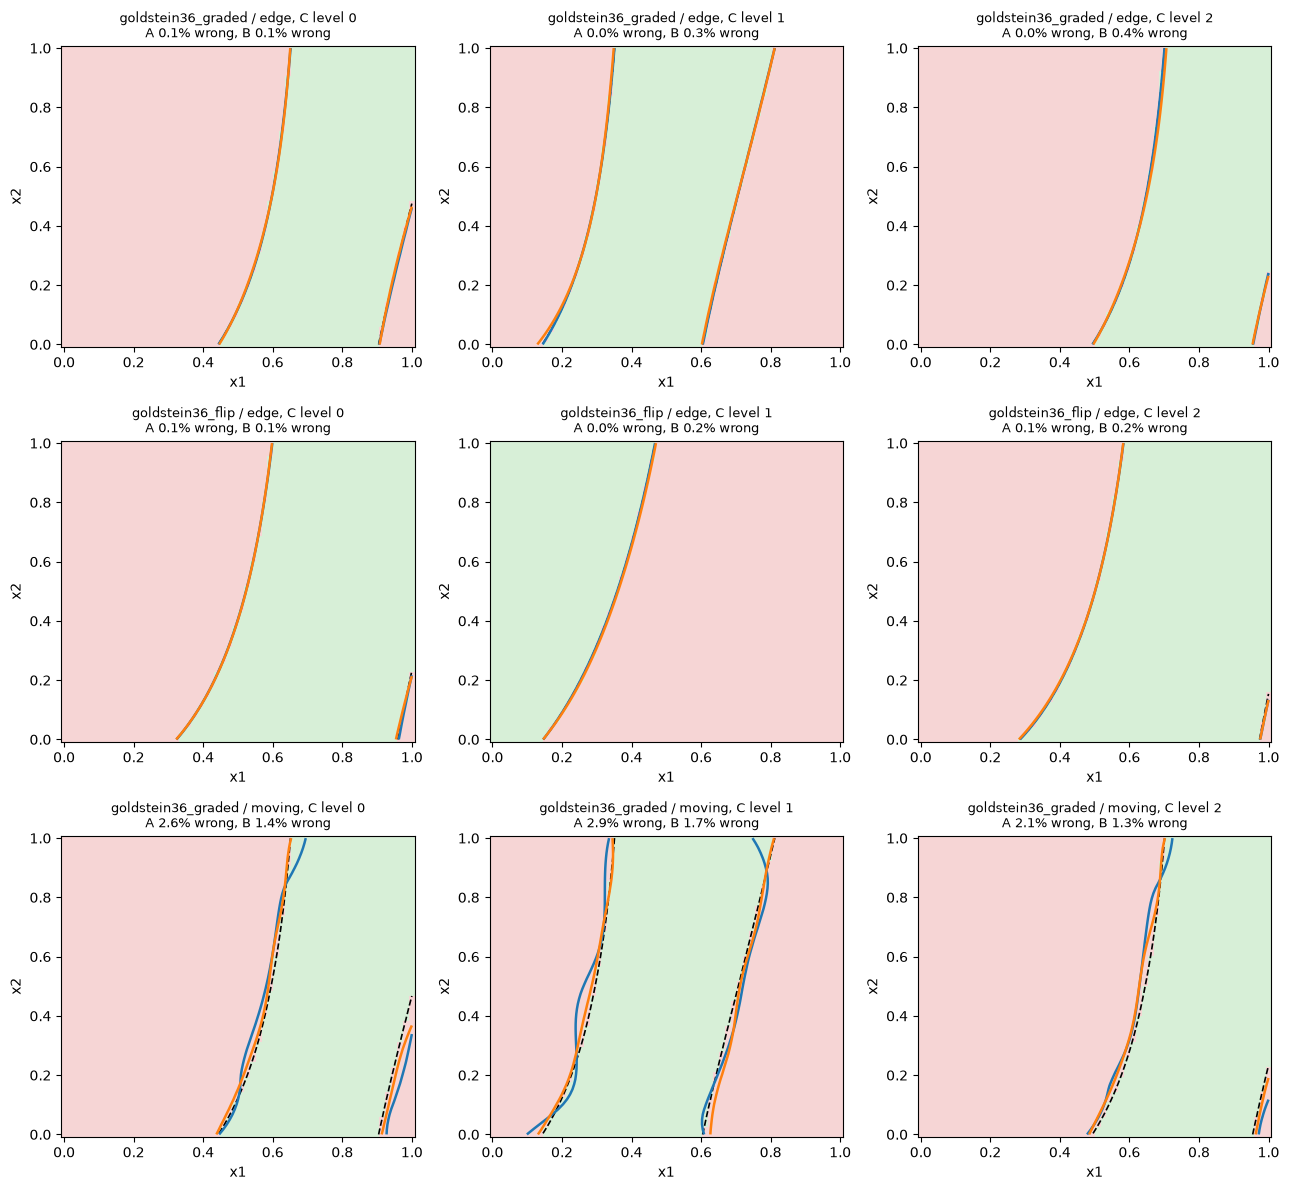

In [7]:
# The worst-case boundary on a slice (seed 1): x1-x2 plane, x4 and D at level 1, one column per
# level of C. Pale fill: true worst-case set (green acceptable); black dashed: true boundary;
# coloured lines: each condition's boundary from its 250 samples.
PALE = ListedColormap(["#f6d5d5", "#d7efd7"])
N = 60
g = np.linspace(0, 1, N)
g1, g2 = np.meshgrid(g, g, indexing="ij")
fig, axes = plt.subplots(len(CASES), 3, figsize=(13, 4.0 * len(CASES)), squeeze=False)
for row, case in enumerate(CASES):
    prob, f = response(case)
    models = {c: fit_surrogate(config.LSE["method"], prob.space, runs[case, c, 1]["w"], runs[case, c, 1]["y"],
                               rng=np.random.default_rng(0)) for c in CONDITIONS}
    for k in range(3):
        d = np.column_stack([g1.ravel(), g2.ravel(), np.full(N * N, 1), np.full(N * N, 1), np.full(N * N, k)])
        truth = worst(f, d, E_TRUE).reshape(N, N)
        ax = axes[row, k]
        ax.pcolormesh(g1, g2, (truth <= prob.threshold).astype(float), cmap=PALE, vmin=0, vmax=1, shading="auto")
        ax.contour(g1, g2, truth, levels=[prob.threshold], colors="black", linewidths=1.2, linestyles="--")
        title = []
        for cond, m in models.items():
            mu = worst(lambda w: m.predict(w)[0], d, E_READ).reshape(N, N)
            ax.contour(g1, g2, mu, levels=[prob.threshold], colors=colors[cond], linewidths=1.8)
            title.append(f"{cond[0]} {100 * np.mean((mu <= prob.threshold) != (truth <= prob.threshold)):.1f}% wrong")
        ax.set_title(f"{case}, C level {k}\n" + ", ".join(title), fontsize=9)
        ax.set_xlabel("x1"); ax.set_ylabel("x2")
plt.tight_layout(); plt.savefig("results/exp0c_boundaries.png", dpi=130); plt.show()

## Insight

**1. Where the worst heading moves with the design, the worst-case straddle (B) is clearly better.**
"moving": B is ahead at every checkpoint and ends at F1 0.987 (every seed 0.985–0.988) against 0.971
(0.965–0.976) for A, with half the false-safe share (1.0% vs 2.0%). A spreads its samples over all of
x3; B concentrates them at x3 ≈ x2, the true worst value (sample histogram). This is the exp1
situation for 40 and 60 kt, whose worst heading lies at 25–55°.

**2. Where the worst heading is the edge, B is faster early but does not hold its lead.** B reaches F1
0.99 at 75 samples (A: 98 on graded, 72 vs 68 on flip) and is near-perfect at 100 (0.999). After about
150 samples it slips (graded: 0.993 at 250, one seed 0.954; flip: 0.998), while A keeps improving to
0.999 with fewer false-safe designs (0.03–0.05% vs 0.10–0.20%).

**3. Why B slips at the edge (from the sample record, not yet confirmed).** After the edge boundary is
resolved, B revisits the same designs at other x3 values: its 214 new samples cover only 75–89
distinct designs (A: 214), the histogram shows a flat spread over x3 besides the spike at 0, and its
own worst-case max straddle goes negative only at 126–188 samples. To certify a worst case as
acceptable, every other x3 must be shown no worse, so near-boundary designs keep being swept along
x3. Those clustered samples are where the late errors appear.

**4. Cost per run** was lower for B on the edge cases (70–80 vs 105–120 minutes) and similar on
"moving" (125–150).

**Reading for the paper.** B targets the requirement itself and wins where it matters most, an
interior worst heading; its late drift at the edge needs a fix before it replaces A (e.g. stop
sampling a design once its worst-case interval excludes tau, or mix in ordinary straddle samples).